# P09 — Anotação dos clusters por marcadores canônicos

**Ponto de partida.** A integração é a escolhida pelo benchmark do P07,
**ComBat** sobre a lognorm escalonada. Os clusters são os do P08: Leiden na
resolução 1,0 sobre o grafo do ComBat, 19 clusters. As amostras passaram por
sorting de CD4⁺, então a maioria é T CD4⁺. O objetivo é anotar os subtipos de
CD4⁺ e identificar as populações contaminantes.

**Como.** Três fontes de evidência, nesta ordem:

1. **marcadores canônicos** da literatura (painel com referências na seção 1):
   % de células que detectam cada marcador e média da expressão, por cluster;
2. **genes diferenciais** de cada cluster contra os demais (Wilcoxon);
3. **conferência independente** no atlas de células T CD4⁺ de Yasumizu et al.
   (2024, *Cell Genomics*): cada célula foi mapeada nos 5 tipos L1 e nos 18 tipos
   L2 do atlas com o Symphony (`raw/run_atlas_mapping.py`). O mapeamento não usa
   a nossa integração nem os nossos clusters.

A decisão de cada cluster está em `functions/anotacao.LEIDEN_P08`, com a
evidência escrita ao lado. Este notebook mostra os números que a sustentam.

Limite de inferência: 7 pacientes, 14 bibliotecas; MB e NP com um paciente
cada. A composição por estímulo (seção 7) é descritiva.

In [1]:
import sys
sys.path.insert(0, "/mnt/SATA/singleCellTaru/src/Reseq")

import warnings
warnings.filterwarnings("ignore")

import anndata as ad
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc
from scipy import stats
from sklearn.metrics import adjusted_rand_score, cohen_kappa_score

from functions import anotacao as an, atlas, benchmark as bm, config, fmt as F, io, plotting
from functions.issues import IssueLog, show

plotting.apply_style()
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 250)
sc.settings.verbosity = 0

NB = "P09_anotacao"
log = IssueLog(NB)
INK = plotting.INK
LIBS, PATS = config.LIBRARIES, config.PATIENTS

In [2]:
main = ad.read_h5ad(io.data_path("P05_integracao", "reseq_raw_integrado", "h5ad"))
integ = ad.read_h5ad(io.data_path("P07_benchmark_integracao", "integracao_escolhida", "h5ad"))
rot = pd.read_parquet(io.data_path("P08_clusterizacao", "clusters", "parquet")).set_index("cell_key")
keys = main.obs["cell_key"].astype(str).to_numpy()
assert (integ.obs["cell_key"].astype(str).to_numpy() == keys).all()
cl = rot.loc[keys, "leiden_final"].astype(str).to_numpy()
mapa = pd.read_parquet(atlas.DIR / "mapeamento" / "mapeamento.parquet").reindex(keys)
azi = bm.azimuth_labels(main.obs).set_index("cell_key").reindex(keys)
a = an.symbol_view(main)
a.obs["cluster"] = pd.Categorical(cl, categories=sorted(set(cl), key=int))
N = a.n_obs
print(f"{F.n(N)} células · {plotting.N_DESIGN}; integração {dict(integ.uns['integracao'])['metodo']} "
      f"({dict(integ.uns['integracao'])['execucao']}); {a.obs['cluster'].nunique()} clusters (Leiden 1,0, P08)")
print(f"mapeadas no atlas: {F.n(mapa['atlas_L1'].notna().sum())} (as que o Azimuth chama de outra linhagem ficaram de fora)")

35.247 células · 14 bibliotecas · 7 pacientes; integração ComBat (combat_esc); 19 clusters (Leiden 1,0, P08)
mapeadas no atlas: 33.999 (as que o Azimuth chama de outra linhagem ficaram de fora)


## 1. O painel de marcadores

Os marcadores de cada tipo e de onde vêm. A linhagem (T, CD4, CD8 e
contaminantes) segue a referência de PBMC do Azimuth (Hao et al., 2021). Os
estados de CD4⁺ seguem os trabalhos que os definiram: naive/memória por
CCR7 e CD62L (*SELL*) em Sallusto et al. (1999) e Mahnke et al. (2013); Treg por
FOXP3 e Helios (*IKZF2*); Th17 por CCR6, RORγt e CD161 (*KLRB1*); Tfh por
CXCR5/PD-1/ICOS; e CD4 citotóxica por GZMB/perforina/granulisina.

In [3]:
painel = pd.DataFrame([{"tipo": t, "marcadores": ", ".join(g), "referências": "; ".join(r)}
                       for t, (g, r) in an.PANEL.items()])
refs = pd.DataFrame([{"chave": k, "referência": v} for k, v in an.REFS.items()])
io.save_table(painel, NB, "painel_marcadores", description="Painel de marcadores canônicos e referências", index=False)
io.save_table(refs, NB, "referencias", description="Referências do painel de marcadores", index=False)
faltam = [g for g in an.panel_genes() if g not in a.var_names]
print("marcadores do painel ausentes dos dados:", faltam or "nenhum")
with pd.option_context("display.max_colwidth", None):
    display(painel)

marcadores do painel ausentes dos dados: nenhum


,tipo,marcadores,referências
0,célula T,"CD3E, CD3D, CD2, TRAC",Hao2021
1,CD4,"CD4, CD40LG",Hao2021
2,CD8,"CD8A, CD8B",Hao2021
3,naive,"CCR7, SELL, LEF1, TCF7",Sallusto1999; Mahnke2013
4,memória,"FAS, S100A4, ANXA1, AQP3",Mahnke2013; Yasumizu2024
5,efetora (Tem),"GZMK, CCL5, KLRB1",Sallusto1999; Szabo2019
6,citotóxica (Temra),"GZMB, PRF1, GNLY, NKG7, GZMH, CX3CR1",Patil2018; Mahnke2013
7,Treg,"FOXP3, IL2RA, CTLA4, IKZF2, TIGIT",Fontenot2003; Thornton2010
8,Th17,"RORC, CCR6, IL23R",AcostaRodriguez2007; Cosmi2008
9,Th2,"GATA3, CCR4",Yasumizu2024


## 2. Perfil de cada cluster no painel

Tamanho do ponto = % de células do cluster que detectam o gene (≥ 1 UMI);
cor = média da lognorm, escalonada por gene entre os clusters (0–1). Os
clusters estão agrupados pela anotação final (seção 4).

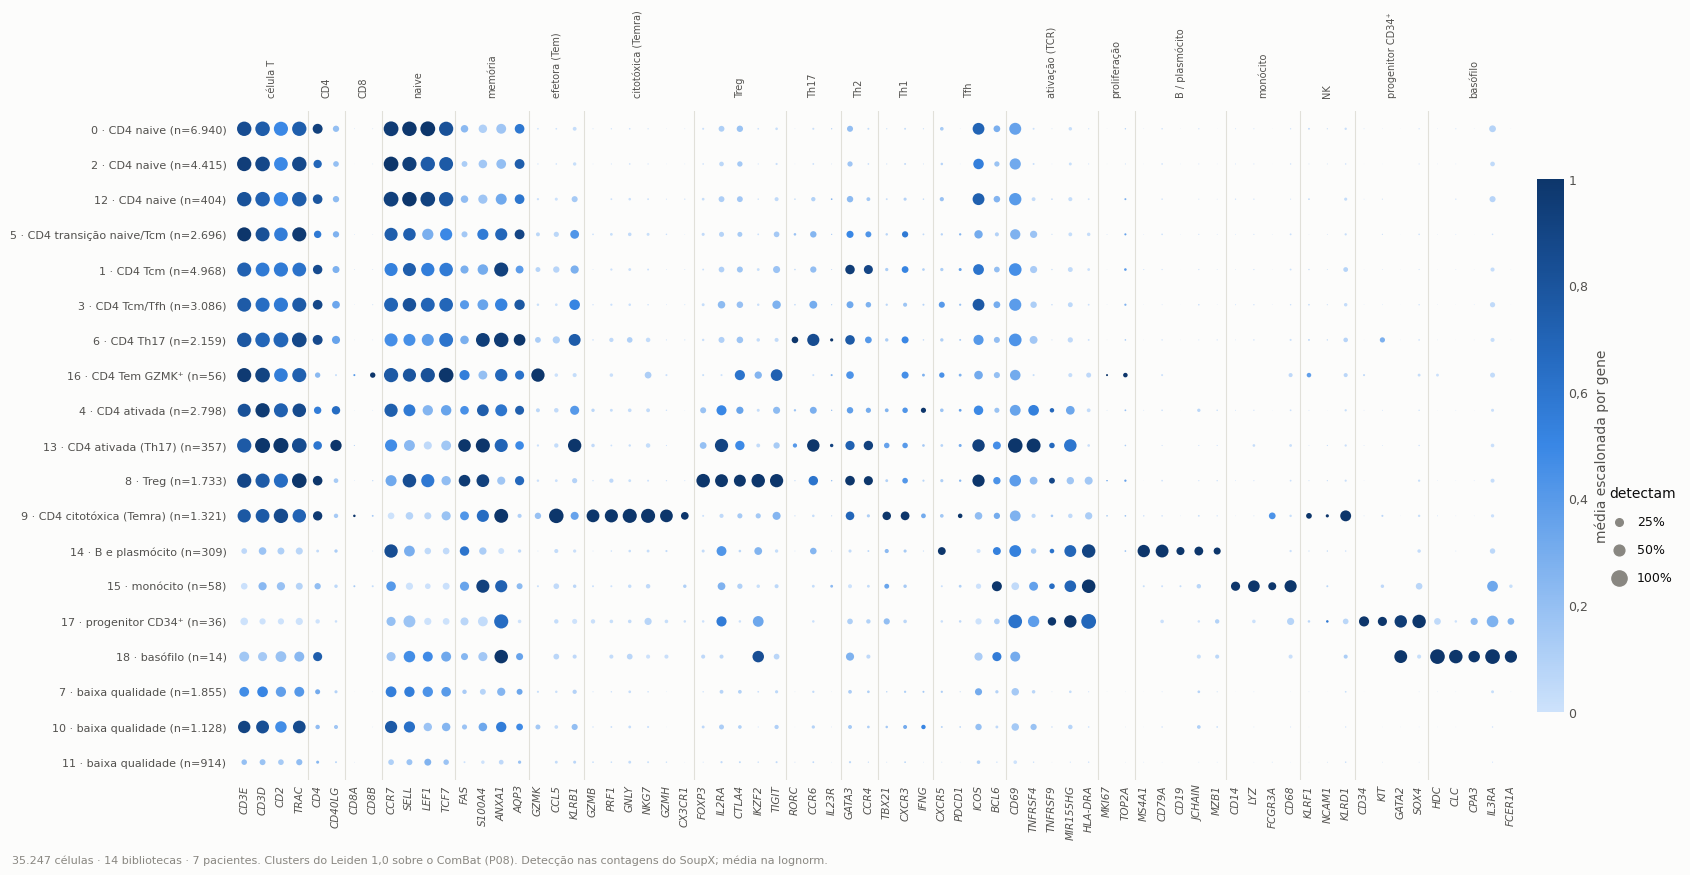

In [4]:
genes = [g for g in an.panel_genes() if g in a.var_names]
frac, mean = an.dot_stats(a, a.obs["cluster"], genes)
ann = pd.DataFrame({c: {"rotulo": v[0], "grupo": v[1], "marcadores": v[2], "evidencia": v[3]}
                    for c, v in an.LEIDEN_P08.items()}).T
assert set(ann.index) == set(a.obs["cluster"].cat.categories), "todo cluster precisa de uma decisão"
n_cl = a.obs["cluster"].value_counts()
ordem = sorted(ann.index, key=lambda c: (an.LABEL_ORDER.index(ann.loc[c, "rotulo"]), -n_cl[c]))
rows_lab = [f"{c} · {ann.loc[c, 'rotulo']} (n={F.n(n_cl[c])})" for c in ordem]
grupos_col = [(t, len([g for g in gs if g in a.var_names])) for t, (gs, _) in an.PANEL.items()]
fig, ax = plt.subplots(figsize=(17, 8.6))
sc_ = an.dotplot(ax, frac, mean, rows=ordem, cols=genes, groups_of_cols=grupos_col)
ax.set_yticklabels(rows_lab)
cb = fig.colorbar(sc_, ax=ax, fraction=0.02, pad=0.01)
cb.set_label("média escalonada por gene")
plotting._style_colorbar(cb)
for v in (0.25, 0.5, 1.0):
    ax.scatter([], [], s=v * 120, c=INK["muted"], label=F.pct(v, 0))
ax.legend(title="detectam", loc="upper left", bbox_to_anchor=(1.06, 0.45), frameon=False, labelspacing=1.2)
plotting.note(fig, f"{F.n(N)} células · {plotting.N_DESIGN}. Clusters do Leiden 1,0 sobre o ComBat (P08). Detecção nas "
                   "contagens do SoupX; média na lognorm.", y=0.0)
fig.tight_layout()
plotting.savefig(fig, NB, "painel_por_cluster", description="Marcadores canônicos por cluster (detecção e média)",
                 data=(frac * 100).round(1).reindex(ordem).rename_axis("cluster").reset_index(), data_index=False)
plt.show()

## 3. Genes diferenciais e escores do painel

Os 12 genes mais diferenciais de cada cluster contra todos os outros
(Wilcoxon na lognorm), e o escore de cada tipo do painel (`score_genes`) em
cada célula, resumido pela mediana do cluster.

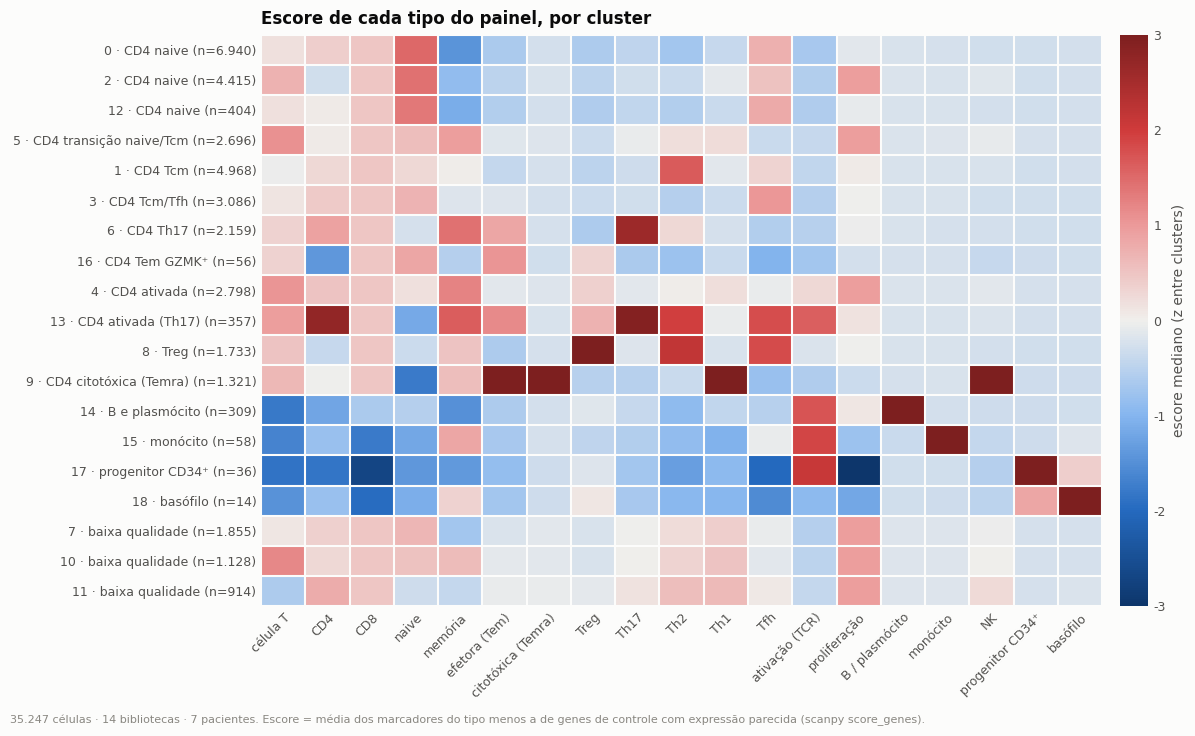

,cluster,rótulo,genes diferenciais (log2FC)
0,0,CD4 naive,"FHIT (3,1), TSHZ2 (2,6), IGF1R (2,3), LEF1 (1,8), RAPGEF6 (1,5), ENSG00000271774 (2,1), CERS6 (2,3), PLCL1 (1,7), PRKCA (1,5), TXK (1,9), MBNL1 (1,2), MAML2 (1,7)"
1,2,CD4 naive,
2,12,CD4 naive,"ENSG00000271893 (7,8), ENSG00000224099 (8,3), TSHZ2 (1,8), ENSG00000271774 (1,4), FHIT (1,5), LEF1 (1,2), IGF1R (1,4), PRKCA (1,0), ANK3 (1,2), PDE3B (1,0), TXK (1,2), ENSG00000235056 (6,3)"
3,5,CD4 transição naive/Tcm,"FTH1 (1,8)"
4,1,CD4 Tcm,"FTH1 (2,1), NR3C1 (2,1), PHACTR2 (2,3), NIBAN1 (2,6), SAMSN1 (1,8), ITGB1 (1,9), FYN (1,5), CNOT6L (1,5), PIK3R1 (1,6), TNFAIP3 (1,7), PPP2R5C (1,3), SESN3 (1,7)"
5,3,CD4 Tcm/Tfh,"ANK3 (1,6), LIMS1 (1,5), SPON1 (2,1), ENSG00000228655 (1,2), ARHGAP15 (1,0), SERINC5 (1,2), ST8SIA1 (1,7), CASK (1,3), TALAM1 (1,4), NEAT1 (1,1), ELMO1 (1,1), KLF12 (1,1)"
6,6,CD4 Th17,"RORA (2,3), IL7R (1,9), EML4 (1,7), ERN1 (2,5), TTC39C (1,5), MYO1F (2,5), PLCB1 (3,7), RORA-AS1 (2,0), ENSG00000227240 (3,7), CD96 (1,9), PDE4D (1,7), RUNX2 (2,4)"
7,16,CD4 Tem GZMK⁺,"LYST (3,7), NUCB2 (3,3), SESTD1 (5,2), GZMK (5,4), MYB (5,5), CCSER2 (2,2), NEK7 (2,4), AFF3 (5,5), BICDL1 (2,3), LDLRAD4 (2,4), NCOA1 (2,2), CASK (2,2)"
8,4,CD4 ativada,"IL32 (1,6), HLA-B (1,1), TMSB10 (1,3), PFN1 (1,4), LTB (1,4), ACTB (1,3), PSME2 (1,7), GAPDH (1,2), ACTG1 (1,4), CFL1 (1,0), PSME1 (1,2), S100A6 (1,3)"
9,13,CD4 ativada (Th17),"IL4I1 (5,2), LTB (2,2), TNFRSF4 (4,2), CLIC1 (3,1), ADAM19 (3,3), ACTB (1,8), FURIN (3,3), CMTM6 (2,5), LCP2 (2,5), SOS1 (2,5), TNFRSF18 (3,7), ACTG1 (2,1)"


In [5]:
sc.tl.rank_genes_groups(a, "cluster", method="wilcoxon", use_raw=False, n_genes=40, pts=True)
dif = []
for c in ordem:
    d = sc.get.rank_genes_groups_df(a, c)
    d = d[(d["logfoldchanges"] > 1) & (d["pvals_adj"] < 0.01)].head(12)
    dif.append({"cluster": c, "rótulo": ann.loc[c, "rotulo"],
                "genes diferenciais (log2FC)": ", ".join(f"{r.names} ({F.f(r.logfoldchanges, 1)})" for r in d.itertuples())})
dif = pd.DataFrame(dif)
io.save_table(dif, NB, "genes_diferenciais", description="Genes mais diferenciais de cada cluster (Wilcoxon)", index=False)
esc = an.module_scores(a)
esc_cl = esc.groupby(a.obs["cluster"].to_numpy()).median().reindex(ordem)
z = (esc_cl - esc_cl.mean()) / esc_cl.std().replace(0, 1)
fig, ax = plt.subplots(figsize=(12, 7.2))
m = z.copy()
m.index = rows_lab
plotting.heatmap(ax, m, center=0, vmin=-3, vmax=3, cbar_label="escore mediano (z entre clusters)", xrotation=45)
ax.set_title("Escore de cada tipo do painel, por cluster")
plotting.note(fig, f"{F.n(N)} células · {plotting.N_DESIGN}. Escore = média dos marcadores do tipo menos a de genes de "
                   "controle com expressão parecida (scanpy score_genes).", y=0.0)
fig.tight_layout()
plotting.savefig(fig, NB, "escores_por_cluster", description="Escores do painel por cluster (mediana, z)",
                 data=esc_cl.rename_axis("cluster").reset_index(), data_index=False)
plt.show()
with pd.option_context("display.max_colwidth", None):
    display(dif)

## 4. A anotação

Para cada cluster: o rótulo, a classe ampla, os marcadores que sustentam a
decisão (com a % de células que os detectam) e o que o atlas diz das mesmas
células.

In [6]:
L1 = mapa["atlas_L1"]
L2 = mapa["atlas_L2"]
linhas = []
for c in ordem:
    msk = (cl == c)
    mk = ann.loc[c, "marcadores"]
    l1 = L1[msk].value_counts(normalize=True)
    l2 = L2[msk].value_counts(normalize=True)
    az = azi.loc[msk, "azimuth_fino"].value_counts(normalize=True)
    linhas.append({"cluster": c, "células": int(msk.sum()), "rótulo": ann.loc[c, "rotulo"], "grupo": ann.loc[c, "grupo"],
                   "marcadores (% que detectam)": ", ".join(f"{g} {F.pct(frac.loc[c, g], 0)}" for g in mk if g in frac.columns),
                   "atlas L1": f"{l1.index[0]} {F.pct(l1.iloc[0], 0)}" if len(l1) else "—",
                   "atlas L2": f"{l2.index[0]} {F.pct(l2.iloc[0], 0)}" if len(l2) else "—",
                   "Azimuth": f"{az.index[0]} {F.pct(az.iloc[0], 0)}" if len(az) else "—",
                   "evidência": ann.loc[c, "evidencia"]})
tab = pd.DataFrame(linhas)
io.save_table(tab, NB, "anotacao_clusters", description="Anotação de cada cluster com a evidência", index=False)
a.obs["anotacao"] = pd.Categorical(ann.loc[cl, "rotulo"].to_numpy(), categories=an.LABEL_ORDER)
a.obs["grupo"] = pd.Categorical(ann.loc[cl, "grupo"].to_numpy(), categories=an.GROUP_ORDER)
res_grupo = a.obs["grupo"].value_counts().reindex(an.GROUP_ORDER)
print("células por classe ampla: " + "; ".join(f"{g} {F.n(v)} ({F.pct(v / N, 1)})" for g, v in res_grupo.items()))
with pd.option_context("display.max_colwidth", None):
    display(tab)

células por classe ampla: CD4 naive 11.759 (33,4%); CD4 memória 12.965 (36,8%); CD4 ativada 3.155 (9,0%); Treg 1.733 (4,9%); CD4 citotóxica 1.321 (3,7%); contaminante 417 (1,2%); baixa qualidade 3.897 (11,1%)


,cluster,células,rótulo,grupo,marcadores (% que detectam),atlas L1,atlas L2,Azimuth,evidência
0,0,6940,CD4 naive,CD4 naive,"CCR7 94%, SELL 90%, LEF1 95%, TCF7 87%",Tnaive 98%,Tnaive 59%,Naive CD4 T cell 99%,"naive clássica (TSHZ2, FHIT, LEF1 nos diferenciais)"
1,2,4415,CD4 naive,CD4 naive,"CCR7 93%, SELL 87%, LEF1 89%, TCF7 83%",Tnaive 98%,Tnaive 71%,Naive CD4 T cell 99%,naive; difere do 0 por genes ribossomais
2,12,404,CD4 naive,CD4 naive,"CCR7 94%, SELL 90%, LEF1 93%, TCF7 89%",Tnaive 79%,Tnaive 52%,Naive CD4 T cell 97%,naive; difere do 0 por dois lncRNAs
3,5,2696,CD4 transição naive/Tcm,CD4 memória,"CCR7 74%, LEF1 55%, S100A4 53%, ANXA1 63%",Tnaive 44%,Tnaive 40%,Naive CD4 T cell 61%,CCR7⁺ com marcadores de memória em parte; o atlas divide 44% naive / 40% Tcm
4,1,4968,CD4 Tcm,CD4 memória,"CCR7 73%, ANXA1 85%, S100A4 48%, GATA3 39%, CCR4 35%",Tcm 57%,TcmTh0 40%,Naive CD4 T cell 77%,"memória central CCR7⁺; inclina a Th2 (GATA3, CCR4); atlas: TcmTh0"
5,3,3086,CD4 Tcm/Tfh,CD4 memória,"CCR7 84%, KLRB1 48%, CXCR5 16%, TIGIT 31%",Tcm 58%,TcmTh0 34%,Naive CD4 T cell 86%,memória central com CXCR5 e TIGIT; atlas: TcmTh0 e TcmTfh
6,6,2159,CD4 Th17,CD4 memória,"CCR6 64%, KLRB1 61%, RORC 19%, S100A4 82%",Tcm 63%,TcmTh17 50%,Naive CD4 T cell 57%,CCR6⁺ KLRB1⁺ (CD161) RORC⁺; atlas: TcmTh17
7,16,56,CD4 Tem GZMK⁺,CD4 memória,"GZMK 77%, TIGIT 59%, CTLA4 45%, CCR7 88%",Tem 51%,TemTph 49%,Naive CD4 T cell 52%,GZMK⁺ TIGIT⁺; atlas: TemTph (49%); poucas células
8,4,2798,CD4 ativada,CD4 ativada,"TNFRSF4 49%, IL2RA 43%, MIR155HG 33%, CD69 51%",Tcm 55%,TcmTh0 22%,Naive CD4 T cell 43%,"ativação pelo TCR (OX40, CD25, MIR155HG); mistura de naive e memória no atlas"
9,13,357,CD4 ativada (Th17),CD4 ativada,"CD69 92%, TNFRSF4 84%, IL2RA 76%, CCR6 67%",Tcm 61%,TcmTh17 49%,Memory CD4 T cell 41%,ativação forte com CCR6/KLRB1; atlas: TcmTh17


## 5. Conferência com o atlas

Para as células que o Azimuth chama de CD4⁺ (critério que não depende de
nenhum dos nossos passos), a concordância entre a nossa anotação e o tipo L1
do atlas. Os rótulos sem equivalente no L1 (ativadas, transição) ficam de
fora. Como comparação, a mesma conta para o Azimuth, nos tipos que ele tem
(naive e Treg).

23.670 células CD4⁺ (Azimuth) com rótulo comparável: concordância com o atlas L1 79,2%, κ de Cohen 0,65
só naive e Treg: nossa anotação 94,7%; Azimuth 65,7%


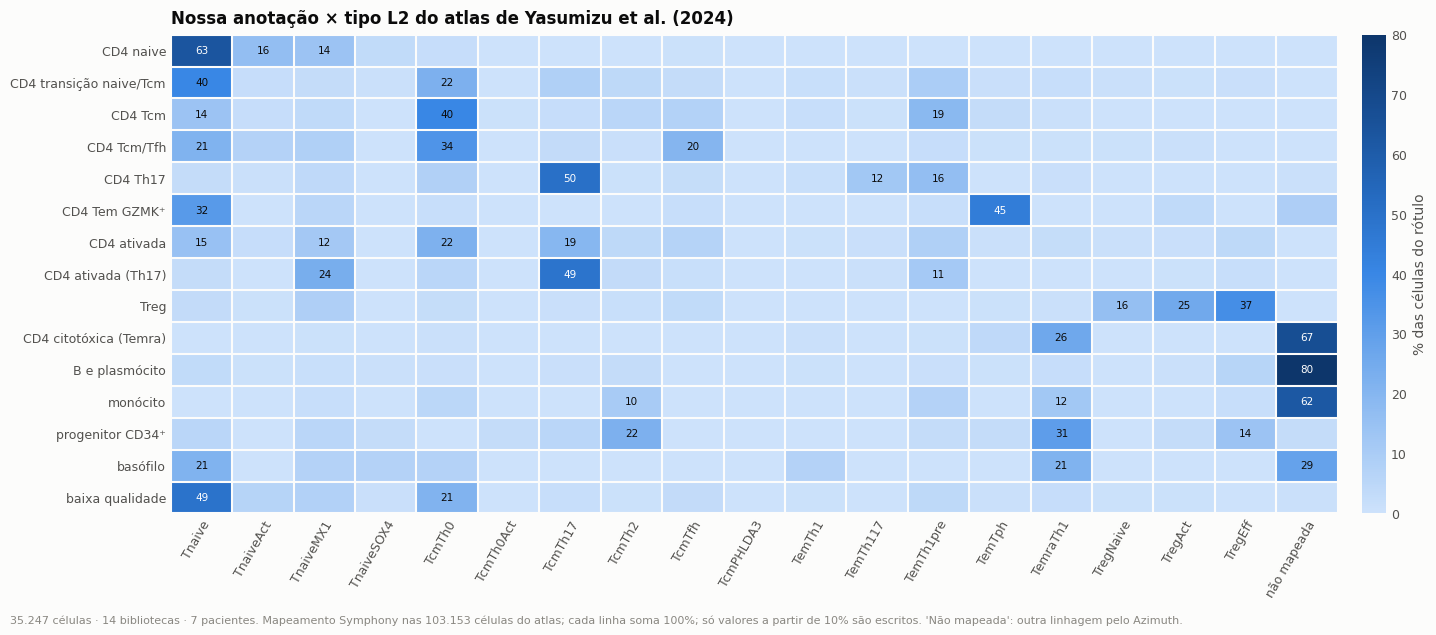

col_0,Tnaive,Tcm,Tem,Temra,Treg
row_0,,,,,
Tnaive,0.823,0.161,0.001,0.001,0.014
Tcm,0.042,0.932,0.000,0.002,0.023
Tem,0.021,0.933,0.012,0.029,0.006
Temra,0.048,0.208,0.000,0.702,0.042
Treg,0.020,0.038,0.001,0.000,0.940


In [7]:
cd4_az = azi[bm.LABEL].isin(["CD4 naive", "CD4 memória", "Treg"]).to_numpy()
nosso_l1 = a.obs["anotacao"].astype(str).map(an.TO_ATLAS_L1)
ok = cd4_az & nosso_l1.notna().to_numpy() & L1.notna().to_numpy()
acc = float((nosso_l1[ok].to_numpy() == L1[ok].to_numpy()).mean())
kappa = float(cohen_kappa_score(nosso_l1[ok], L1[ok]))
rec = pd.crosstab(L1[ok].to_numpy(), nosso_l1[ok].to_numpy(), normalize="index").reindex(index=atlas.L1, columns=atlas.L1)
az_l1 = azi["azimuth_fino"].map({"Naive CD4 T cell": "Tnaive", "Treg cell": "Treg"})
ok_az = cd4_az & az_l1.notna().to_numpy() & L1.notna().to_numpy()
acc_az = float((az_l1[ok_az].to_numpy() == L1[ok_az].to_numpy()).mean())
nosso_nt = nosso_l1.isin(["Tnaive", "Treg"]).to_numpy() & ok
acc_nt = float((nosso_l1[nosso_nt].to_numpy() == L1[nosso_nt].to_numpy()).mean())
print(f"{F.n(ok.sum())} células CD4⁺ (Azimuth) com rótulo comparável: concordância com o atlas L1 {F.pct(acc, 1)}, "
      f"κ de Cohen {F.f(kappa, 2)}")
print(f"só naive e Treg: nossa anotação {F.pct(acc_nt, 1)}; Azimuth {F.pct(acc_az, 1)}")
io.save_table(rec, NB, "recall_atlas_L1", description="Para cada tipo L1 do atlas, a fração que a nossa anotação dá a cada tipo")
ct2 = pd.crosstab(a.obs["anotacao"].astype(str).to_numpy(), L2.fillna("não mapeada").to_numpy(), normalize="index")
ct2 = ct2.reindex(index=[l for l in an.LABEL_ORDER if l in ct2.index], columns=atlas.L2 + ["não mapeada"]).fillna(0)
fig, ax = plt.subplots(figsize=(14.5, 6.2))
plotting.heatmap(ax, ct2 * 100, vmin=0, vmax=80, fmt=".0f", annotate_above=10, cbar_label="% das células do rótulo",
                 xrotation=60)
ax.set_title("Nossa anotação × tipo L2 do atlas de Yasumizu et al. (2024)")
plotting.note(fig, f"{F.n(N)} células · {plotting.N_DESIGN}. Mapeamento Symphony nas 103.153 células do atlas; cada linha soma "
                   "100%; só valores a partir de 10% são escritos. 'Não mapeada': outra linhagem pelo Azimuth.", y=0.0)
fig.tight_layout()
plotting.savefig(fig, NB, "anotacao_x_atlas", description="Anotação por marcadores × tipo L2 do atlas",
                 data=(ct2 * 100).round(1).rename_axis("anotacao").reset_index(), data_index=False)
plt.show()
rec.round(3)

## 6. A anotação na UMAP

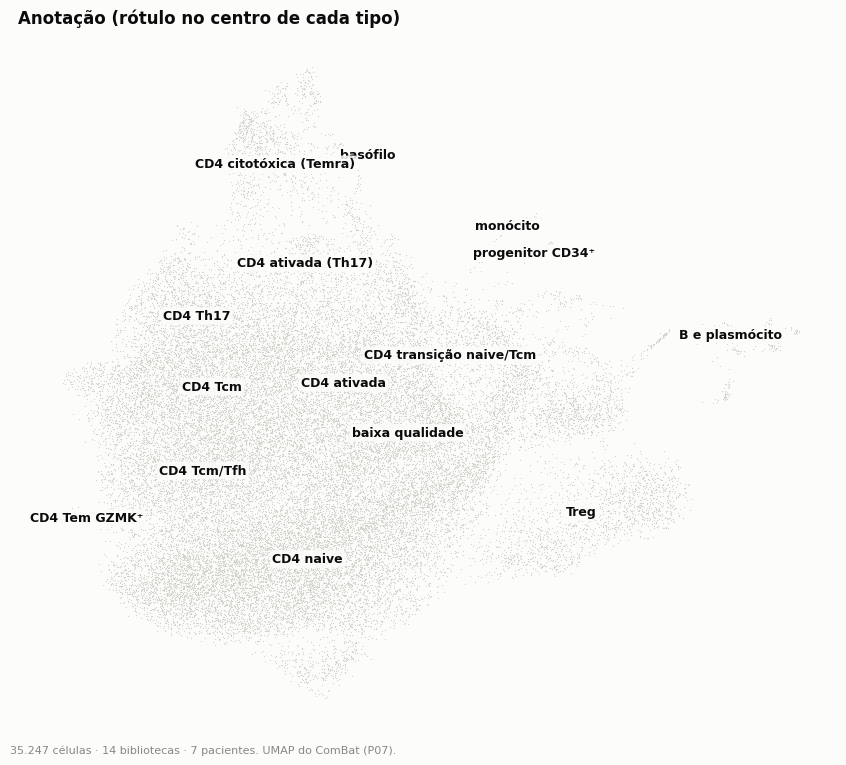

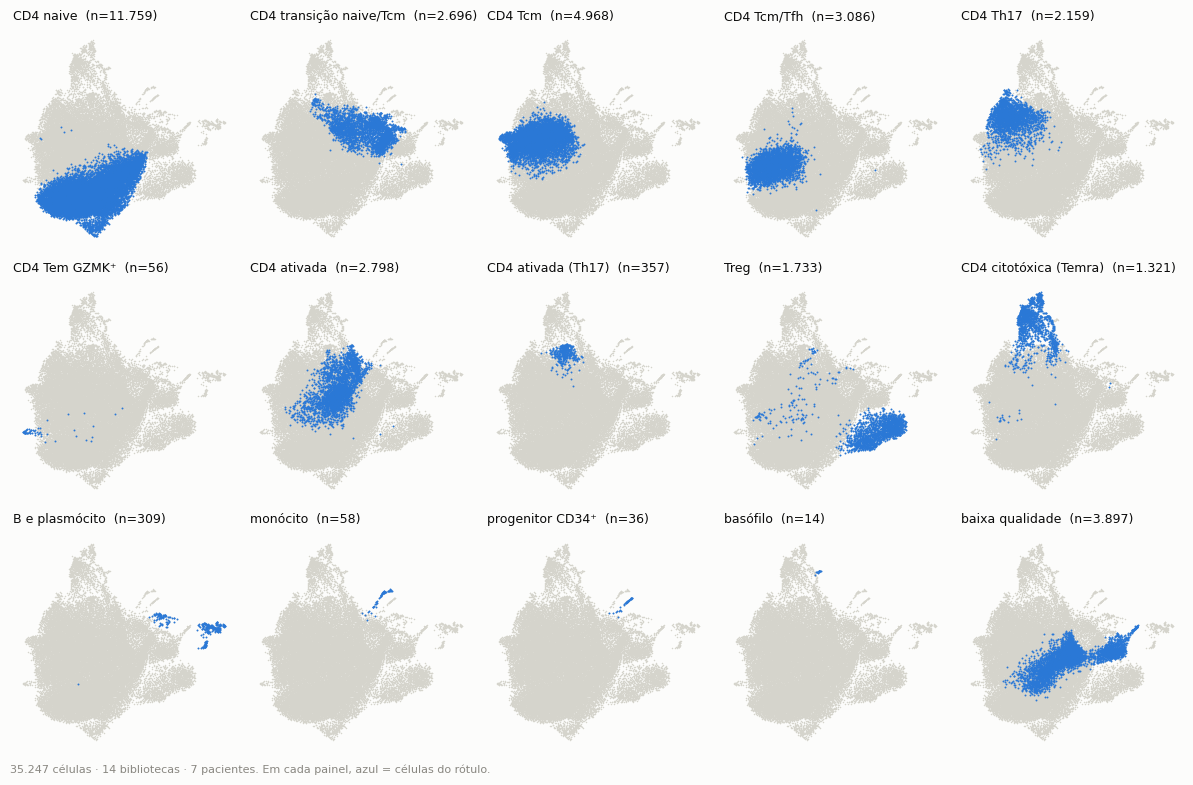

In [8]:
um = integ.obsm["X_umap"]
fig, ax = plt.subplots(figsize=(8.5, 7.5))
plotting.umap_labeled(ax, um, a.obs["anotacao"].astype(str).to_numpy(), s=0.8,
                      title="Anotação (rótulo no centro de cada tipo)")
plotting.note(fig, f"{F.n(N)} células · {plotting.N_DESIGN}. UMAP do ComBat (P07).", y=0.0)
fig.tight_layout()
plotting.savefig(fig, NB, "umap_anotacao", description="UMAP com a anotação",
                 data=a.obs["anotacao"].value_counts().rename("células").rename_axis("anotacao").reset_index(), data_index=False)
plt.show()
labs_presentes = [l for l in an.LABEL_ORDER if (a.obs["anotacao"] == l).any()]
fig = plotting.umap_highlight_grid(um, a.obs["anotacao"].astype(str).to_numpy(), order=labs_presentes, ncols=5, panel=2.4,
                                   s=1.2)
plotting.note(fig, f"{F.n(N)} células · {plotting.N_DESIGN}. Em cada painel, azul = células do rótulo.", y=0.0)
plotting.savefig(fig, NB, "umap_por_rotulo", description="UMAP com cada rótulo em destaque",
                 data=a.obs["anotacao"].value_counts().rename("células").rename_axis("anotacao").reset_index(), data_index=False)
plt.show()

## 7. Composição por biblioteca e estímulo

Fração de cada biblioteca em cada rótulo e, para os estados de CD4⁺, o par
estimulado × não estimulado de cada paciente (n = 7; descritivo: o menor p
exato possível é 0,016).

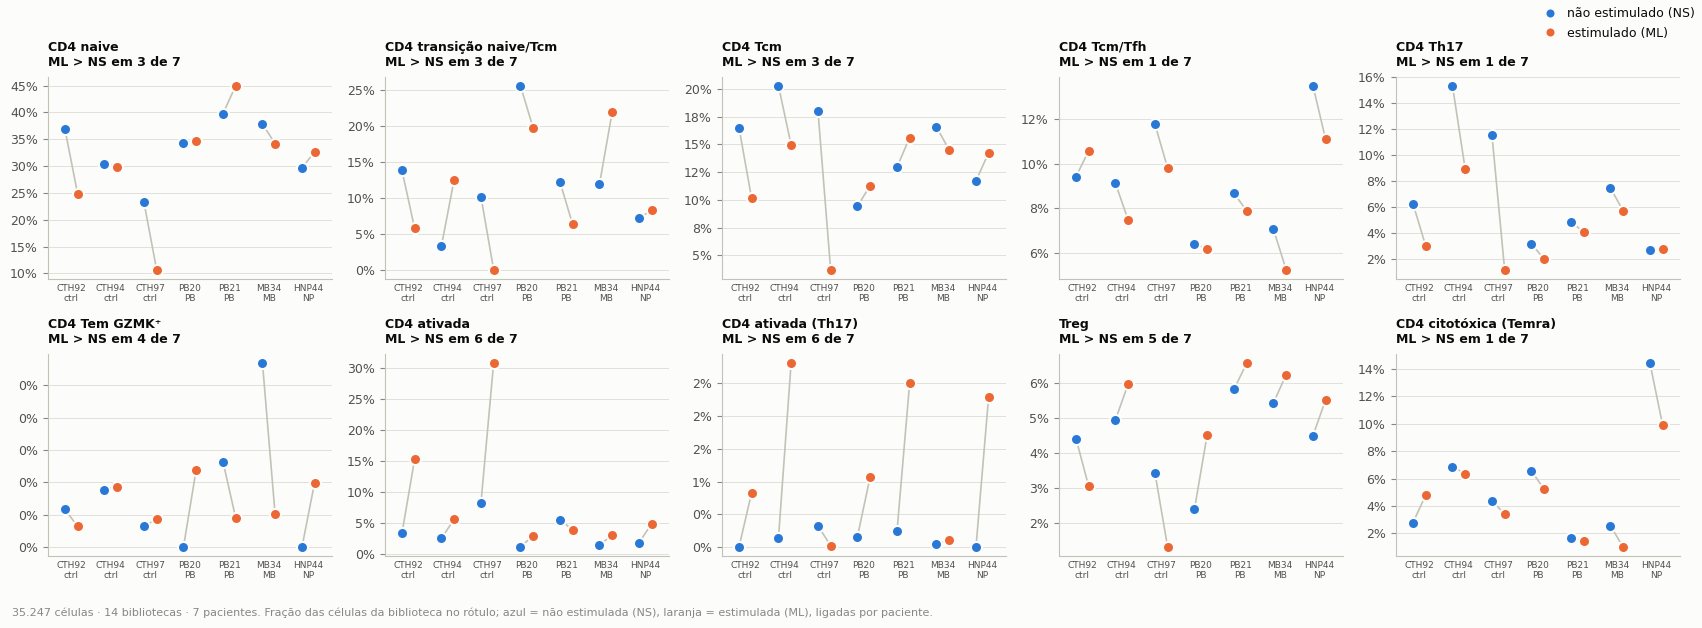

,mediana NS,mediana ML,pacientes com ML > NS,p (Wilcoxon exato),p (BH)
rótulo,,,,,
CD4 naive,0.3435,0.3262,3,0.4688,0.6696
CD4 transição naive/Tcm,0.1192,0.0832,3,0.8125,0.9028
CD4 Tcm,0.1651,0.1424,3,0.3750,0.6250
CD4 Tcm/Tfh,0.0912,0.0789,1,0.0781,0.1953
CD4 Th17,0.0628,0.0306,1,0.0312,0.1562
CD4 Tem GZMK⁺,0.0012,0.0010,4,1.0000,1.0000
CD4 ativada,0.0254,0.0488,6,0.0469,0.1562
CD4 ativada (Th17),0.0014,0.0107,6,0.0469,0.1562
Treg,0.0450,0.0553,5,0.6875,0.8594


In [9]:
lib = main.obs["library_id"].astype(str).to_numpy()
comp = pd.crosstab(a.obs["anotacao"].astype(str).to_numpy(), lib, normalize="columns").reindex(
    index=labs_presentes, columns=LIBS).fillna(0)
io.save_table(comp, NB, "composicao_por_biblioteca", description="Fração das células de cada biblioteca em cada rótulo")
estados = [l for l in labs_presentes if l not in ("baixa qualidade", "B e plasmócito", "monócito", "progenitor CD34⁺",
                                                  "basófilo")]
lin = []
for l in estados:
    v = comp.loc[l]
    ns = pd.Series({p: v[f"{p}_NS"] for p in PATS})
    ml = pd.Series({p: v[f"{p}_ML"] for p in PATS})
    d = ml - ns
    pval = float(stats.wilcoxon(ml, ns, method="exact").pvalue) if (d != 0).all() else np.nan
    lin.append({"rótulo": l, "mediana NS": float(ns.median()), "mediana ML": float(ml.median()),
                "pacientes com ML > NS": int((d > 0).sum()), "p (Wilcoxon exato)": pval})
estim = pd.DataFrame(lin).set_index("rótulo")
pv = estim["p (Wilcoxon exato)"].dropna().sort_values()
estim["p (BH)"] = (pv * len(pv) / np.arange(1, len(pv) + 1))[::-1].cummin()[::-1].clip(upper=1).reindex(estim.index)
io.save_table(estim, NB, "estimulo_por_rotulo", description="Fração de cada estado de CD4⁺ por biblioteca, ML × NS (n = 7)")
ncol = 5
nrow = int(np.ceil(len(estados) / ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(3.4 * ncol, 3.0 * nrow), squeeze=False)
for i, l in enumerate(estados):
    ax = axes[i // ncol][i % ncol]
    plotting.paired_dots(ax, comp.loc[l])
    plotting.percent(ax, "y")
    ax.set_title(f"{l}\nML > NS em {estim.loc[l, 'pacientes com ML > NS']} de 7", fontsize=9)
    ax.tick_params(axis="x", labelsize=6.5)
for k in range(len(estados), nrow * ncol):
    axes[k // ncol][k % ncol].axis("off")
plotting.stim_legend(fig, loc="upper right")
plotting.note(fig, f"{F.n(N)} células · {plotting.N_DESIGN}. Fração das células da biblioteca no rótulo; azul = não "
                   "estimulada (NS), laranja = estimulada (ML), ligadas por paciente.", y=0.0)
fig.tight_layout(rect=(0, 0.02, 1, 0.97))
plotting.savefig(fig, NB, "estimulo_por_rotulo", description="Fração de cada estado de CD4⁺, NS × ML por paciente",
                 data=comp.loc[estados].rename_axis("anotacao").reset_index(), data_index=False)
plt.show()
estim.round(4)

## 8. Rótulos gravados

* `anotacao.parquet`: por célula, o cluster, o rótulo, a classe ampla, o tipo
  L1/L2 do atlas com a fração de votos e o Azimuth;
* `rotulos_benchmark.parquet`: os rótulos que o P12 usa no lugar do Azimuth —
  `anotacao` (sem "baixa qualidade") e `atlas_L1`/`atlas_L2` (só nas células
  que o Azimuth chama de CD4⁺, critério independente dos nossos passos).

In [10]:
out = pd.DataFrame({"cell_key": keys, "library_id": lib, "cluster_leiden": cl,
                    "anotacao": a.obs["anotacao"].astype(str).to_numpy(), "grupo": a.obs["grupo"].astype(str).to_numpy(),
                    "atlas_L1": L1.to_numpy(), "atlas_L1_prob": mapa["atlas_L1_prob"].to_numpy(),
                    "atlas_L2": L2.to_numpy(), "atlas_L2_prob": mapa["atlas_L2_prob"].to_numpy(),
                    "azimuth_fino": azi["azimuth_fino"].to_numpy(), "azimuth_grupo": azi[bm.LABEL].astype(str).to_numpy()})
io.save_data(out, NB, "anotacao", description="Anotação por marcadores dos clusters do P08, atlas (Symphony) e Azimuth, por célula")
rb = pd.DataFrame({"cell_key": keys,
                   "anotacao": out["anotacao"].where(out["anotacao"] != "baixa qualidade"),
                   "atlas_L1": out["atlas_L1"].where(cd4_az),
                   "atlas_L2": out["atlas_L2"].where(cd4_az)})
io.save_data(rb, NB, "rotulos_benchmark", description="Rótulos para o benchmark de integração (P12): anotação e atlas")
print(rb.drop(columns="cell_key").notna().sum().to_string())

anotacao    31350
atlas_L1    32340
atlas_L2    32340


## Problemas encontrados

In [11]:
n_cont = int((out["grupo"] == "contaminante").sum())
n_bq = int((out["grupo"] == "baixa qualidade").sum())
log.add("INFO", "conferência com o atlas", "[VERIFICAÇÃO] a anotação por marcadores concorda com o atlas independente",
        evidence=f"{F.pct(acc, 1)} de concordância com o tipo L1 do atlas (κ {F.f(kappa, 2)}) em {F.n(ok.sum())} células CD4⁺",
        impact="os rótulos de CD4⁺ têm apoio de uma referência externa curada",
        recommendation="nenhuma")
log.add("MINOR", "contaminantes", "há populações não-T na amostra separada por CD4⁺",
        evidence=f"{F.n(n_cont)} células ({F.pct(n_cont / N, 1)}): " + ", ".join(
            f"{l} {F.n((out['anotacao'] == l).sum())}" for l in ["B e plasmócito", "monócito", "progenitor CD34⁺", "basófilo"]),
        impact="a pureza do sorting é alta, mas essas células formam clusters próprios",
        recommendation="excluir os contaminantes antes de análises de CD4⁺; não usar seus clusters como estados de T")
log.add("MINOR", "baixa qualidade", "três clusters são definidos por pouco conteúdo de RNA, não por identidade",
        evidence=f"{F.n(n_bq)} células nos clusters 7, 10 e 11",
        impact="ficam sem rótulo de tipo no benchmark",
        recommendation="excluir ou tratar à parte; o cluster 10 é sobretudo de CTH97 (biblioteca de baixa complexidade)")
log.add("MINOR", "CD4 citotóxica e NK", "o cluster citotóxico tem uma minoria com marcadores de NK",
        evidence=f"cluster 9: KLRF1 em {F.pct(frac.loc['9', 'KLRF1'], 0)}, CD3E em {F.pct(frac.loc['9', 'CD3E'], 0)}",
        impact="parte do sinal citotóxico pode vir de NK residuais",
        recommendation="na análise do cluster, separar as células CD3⁻ KLRF1⁺")
issues = log.save()
print(log.summary().to_string())
show(issues)

severity
CRITICAL    0
MAJOR       0
MINOR       3
INFO        1


severity,location,problem,evidence,impact,recommendation
MINOR,contaminantes,há populações não-T na amostra separada por CD4⁺,"417 células (1,2%): B e plasmócito 309, monócito 58, progenitor CD34⁺ 36, basófilo 14","a pureza do sorting é alta, mas essas células formam clusters próprios",excluir os contaminantes antes de análises de CD4⁺; não usar seus clusters como estados de T
MINOR,baixa qualidade,"três clusters são definidos por pouco conteúdo de RNA, não por identidade","3.897 células nos clusters 7, 10 e 11",ficam sem rótulo de tipo no benchmark,excluir ou tratar à parte; o cluster 10 é sobretudo de CTH97 (biblioteca de baixa complexidade)
MINOR,CD4 citotóxica e NK,o cluster citotóxico tem uma minoria com marcadores de NK,"cluster 9: KLRF1 em 14%, CD3E em 76%",parte do sinal citotóxico pode vir de NK residuais,"na análise do cluster, separar as células CD3⁻ KLRF1⁺"
INFO,conferência com o atlas,[VERIFICAÇÃO] a anotação por marcadores concorda com o atlas independente,"79,2% de concordância com o tipo L1 do atlas (κ 0,65) em 23.670 células CD4⁺",os rótulos de CD4⁺ têm apoio de uma referência externa curada,nenhuma


## Conclusão

**Os 19 clusters do Leiden (sobre o ComBat) foram anotados por marcadores
canônicos:**

| classe | clusters | células |
| --- | --- | --- |
| CD4 naive (CCR7⁺ SELL⁺ LEF1⁺ TCF7⁺) | 0, 2, 12 | 33,4% |
| CD4 memória: Tcm (1), Tcm/Tfh (3), transição naive/Tcm (5), Th17 (6), Tem GZMK⁺ (16) | 1, 3, 5, 6, 16 | 36,8% |
| CD4 ativada pelo TCR (TNFRSF4, IL2RA, MIR155HG, CD69) | 4, 13 | 9,0% |
| Treg (FOXP3⁺ IKZF2⁺) | 8 | 4,9% |
| CD4 citotóxica (GZMB, PRF1, GNLY) | 9 | 3,7% |
| contaminantes: B/plasmócito (14), monócito (15), progenitor CD34⁺ (17), basófilo (18) | 14, 15, 17, 18 | 1,2% (417) |
| baixa qualidade (pouco RNA) | 7, 10, 11 | 11,1% |

**Conferência independente.** Nas 23.670 células CD4⁺ comparáveis, a
anotação concorda com o tipo L1 do atlas de Yasumizu et al. em 79,2% (κ 0,65).
Em naive e Treg chega a 94,7%, contra 65,7% do Azimuth automático do Cell
Ranger. A maior divergência é o Tem do atlas, que aqui cai quase todo em Tcm
(93%). O painel não separa bem memória central e efetora fora do eixo CCR7.

**Estímulo (descritivo, n = 7).** As duas classes ativadas têm mais células
nas bibliotecas estimuladas em 6 de 7 pacientes (p exato 0,047; BH 0,16). O
Th17 em repouso vai na direção oposta (1 de 7), coerente com parte dele
passar ao estado ativado com o estímulo.

Rótulos: `dataReseq/P09_anotacao/anotacao.parquet` e
`rotulos_benchmark.parquet`.